# Genre Identification

This notebook builds the classifier that predicts a song's genre (`country`, `misc`, `pop`, `rap`, `rb`, `rock`) from its lyrics, and produces the test-set submission.

It starts from the cleaned text saved by `Preprocessing.ipynb` (stopwords removed, verbs lemmatised, structure tags stripped) and covers:
1. Additional preprocessing: removing the vocabulary cap, and Chi-squared feature selection.
2. Comparing algorithms on a stratified hold-out set.
3. Hyperparameter tuning with stratified cross-validation.
4. Per-class decision offsets to handle class imbalance.
5. Performance assessment and error analysis.
6. Final training on the full training set and the submission file.

**Metric.** Genres are very imbalanced (pop 41%, country 2.6%), so we report **macro-F1**: every genre counts equally, and a model that ignores the minority genres gets no credit for high accuracy. Accuracy is shown alongside for reference.

## 1. Setup

In [1]:
import os
import sys
import time
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.feature_selection import SelectKBest, chi2
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC
from sklearn.linear_model import SGDClassifier, LogisticRegression
from sklearn.naive_bayes import ComplementNB
from sklearn.metrics import f1_score, accuracy_score, classification_report, confusion_matrix

sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 5)
RANDOM_STATE = 42

## 2. Load Preprocessed Data

We reuse the same 80/20 stratified split (`random_state=42`) as the benchmark in `Preprocessing.ipynb`, so the scores here are directly comparable with that notebook (best there: 0.505 macro-F1).

In [2]:
with open('../tmp/preprocessed_data.pickle', 'rb') as f:
    data = pickle.load(f)

X_text = data['train_clean_genre'].values
X_test_text = data['test_clean_genre'].values
y = data['y_train']
classes = np.array(data['classes'])

test_ids = pd.read_csv('../dataset/test.csv', usecols=['id'])['id'].values

train_idx, val_idx = train_test_split(
    np.arange(len(y)), test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
y_tr, y_val = y[train_idx], y[val_idx]

print(f"Classes: {classes.tolist()}")
print(f"Train fold: {len(train_idx):,} | Validation fold: {len(val_idx):,} | Test: {len(X_test_text):,}")

Classes: ['country', 'misc', 'pop', 'rap', 'rb', 'rock']
Train fold: 107,973 | Validation fold: 26,994 | Test: 33,742


## 3. Additional Preprocessing

### 3.1 Removing the vocabulary cap

In `Preprocessing.ipynb` every vectorizer was capped at 5,000 features. That cap keeps only the most frequent terms, and these are mostly shared by all genres (`love`, `know`, `go`). The rarer terms, such as slang, place names and genre-specific bigrams, carry most of the genre signal.

Here we keep every unigram and bigram that appears in at least 2 songs (`min_df=2`, the value chosen by the grid search in Section 5). This removes one-off tokens and typos but keeps the vocabulary rich. All other settings stay as before (sublinear TF, L2 normalisation, `max_df=0.85`).

In [3]:
tfidf_params = dict(
    ngram_range=(1, 2), min_df=2, max_df=0.85,
    sublinear_tf=True, norm='l2', token_pattern=r"(?u)\b\w+\b"
)

t0 = time.time()
vec = TfidfVectorizer(**tfidf_params)
X_tr = vec.fit_transform(X_text[train_idx])
X_val = vec.transform(X_text[val_idx])
print(f"Vectorised in {time.time() - t0:.0f}s")

n_bigrams = sum(' ' in t for t in vec.get_feature_names_out())
print(f"Vocabulary size: {X_tr.shape[1]:,} features ({X_tr.shape[1] - n_bigrams:,} unigrams, {n_bigrams:,} bigrams)")
print(f"Previous cap: 5,000 features")

Vectorised in 22s
Vocabulary size: 1,107,062 features (69,866 unigrams, 1,037,196 bigrams)
Previous cap: 5,000 features


### 3.2 Feature selection with Chi-squared

With hundreds of thousands of features, we test whether keeping only the `k` terms most associated with the genre label (Chi-squared statistic) helps. The ranking is computed on the training fold only, so the validation fold is never used to choose features. A LinearSVC (`C=0.1`) is used as the probe model.

,k,Macro-F1
0,5000,0.4978
1,20000,0.5121
2,50000,0.5198
3,100000,0.5235
4,300000,0.5278
5,1107062,0.5284


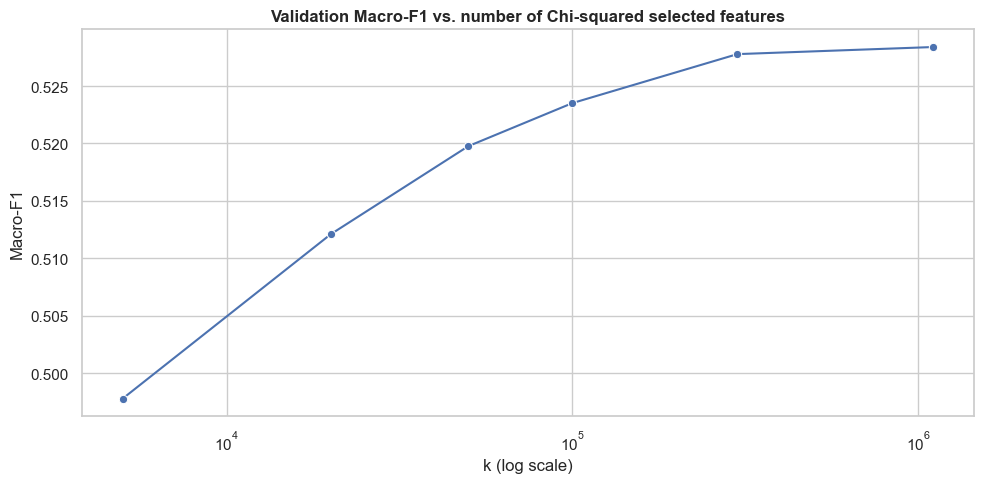

In [4]:
chi2_scores, _ = chi2(X_tr, y_tr)
feature_rank = np.argsort(-np.nan_to_num(chi2_scores))

k_values = [5_000, 20_000, 50_000, 100_000, 300_000, X_tr.shape[1]]
chi2_results = []
for k in k_values:
    cols = feature_rank[:k]
    clf = LinearSVC(C=0.1, class_weight='balanced').fit(X_tr[:, cols], y_tr)
    preds = clf.predict(X_val[:, cols])
    chi2_results.append({'k': k, 'Macro-F1': f1_score(y_val, preds, average='macro')})

chi2_df = pd.DataFrame(chi2_results)
display(chi2_df.round(4))

ax = sns.lineplot(data=chi2_df, x='k', y='Macro-F1', marker='o')
ax.set_xscale('log')
ax.set_title('Validation Macro-F1 vs. number of Chi-squared selected features', weight='bold')
ax.set_xlabel('k (log scale)')
plt.tight_layout()
plt.show()

**Reading the curve.** Macro-F1 rises steadily with `k` (0.498 at 5k, the size of the old cap, up to 0.528 at 300k) and then flattens. Keeping the full vocabulary scores as well as any `k`, because the L2-regularised linear model already gives near-zero weight to uninformative terms. We therefore **do not apply Chi-squared selection** in the final model. It is still useful to choose a reduced feature set for the slower Logistic Regression below.

## 4. Model Comparison (hold-out)

We compare four linear-model families that are standard for sparse, high-dimensional text:
- **Complement Naive Bayes:** a fast probabilistic baseline designed for imbalanced text classes.
- **SGDClassifier (modified Huber loss):** a linear model trained with stochastic gradient descent.
- **LinearSVC:** a linear SVM.
- **Logistic Regression:** fitted on the top 100k Chi-squared features, because the full matrix makes it very slow.

All discriminative models use `class_weight='balanced'` so minority genres are not ignored.

In [5]:
top100k = feature_rank[:100_000]

models = {
    'ComplementNB (alpha=0.3)': (ComplementNB(alpha=0.3), None),
    'SGD modified_huber': (SGDClassifier(loss='modified_huber', alpha=2e-5, class_weight='balanced',
                                         random_state=RANDOM_STATE), None),
    'LinearSVC (C=0.1)': (LinearSVC(C=0.1, class_weight='balanced'), None),
    'LogisticRegression (C=10, top-100k chi2)': (LogisticRegression(C=10, class_weight='balanced', max_iter=500), top100k),
}

comparison = []
for name, (model, cols) in models.items():
    A_tr = X_tr if cols is None else X_tr[:, cols]
    A_val = X_val if cols is None else X_val[:, cols]
    t0 = time.time()
    model.fit(A_tr, y_tr)
    preds = model.predict(A_val)
    comparison.append({
        'Model': name,
        'Macro-F1': f1_score(y_val, preds, average='macro'),
        'Accuracy': accuracy_score(y_val, preds),
        'Fit time (s)': time.time() - t0,
    })

comparison_df = pd.DataFrame(comparison).sort_values('Macro-F1', ascending=False).reset_index(drop=True)
display(comparison_df.round(4))

,Model,Macro-F1,Accuracy,Fit time (s)
0,LinearSVC (C=0.1),0.5284,0.6537,4.9915
1,SGD modified_huber,0.5197,0.6529,3.3029
2,"LogisticRegression (C=10, top-100k chi2)",0.5128,0.6137,38.0689
3,ComplementNB (alpha=0.3),0.3830,0.6466,0.3847


**Observations.**
- **LinearSVC** is the best and also one of the fastest models.
- **ComplementNB** reaches decent accuracy but a much lower macro-F1: it favours the large genres and does poorly on the small ones.
- **Logistic Regression** is slower and worse, even on the reduced feature set.

LinearSVC goes forward to tuning.

## 5. Hyperparameter Tuning (Stratified 3-fold CV)

We tune the vectorizer and the classifier together in a single `Pipeline`. The TF-IDF vocabulary and IDF weights are then re-fitted inside every training fold, so the held-out fold never leaks into the features. The grid covers:
- `ngram_range`: unigrams only vs. unigrams + bigrams
- `min_df`: 2 vs. 5
- `C` (inverse regularisation strength): 0.05, 0.1, 0.2

> The grid search takes ~5 minutes on 4 cores and refits the vectorizer 36 times, so the cell is commented out, as the brief allows. Its results are summarised in the next cell, and the chosen parameters are used directly from Section 6 onwards.

In [6]:
# pipe = Pipeline([
#     ('tfidf', TfidfVectorizer(max_df=0.85, sublinear_tf=True, token_pattern=r"(?u)\b\w+\b")),
#     ('clf', LinearSVC(class_weight='balanced')),
# ])
# param_grid = {
#     'tfidf__ngram_range': [(1, 1), (1, 2)],
#     'tfidf__min_df': [2, 5],
#     'clf__C': [0.05, 0.1, 0.2],
# }
# grid = GridSearchCV(
#     pipe, param_grid, scoring='f1_macro',
#     cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE),
#     n_jobs=4, verbose=1
# )
# grid.fit(data['train_clean_genre'], y)
# display(pd.DataFrame(grid.cv_results_)[['params', 'mean_test_score', 'std_test_score']]
#         .sort_values('mean_test_score', ascending=False))
# print(grid.best_params_)

**Grid search results** (mean macro-F1 over 3 folds, ± std):

| ngram_range | min_df | C | CV Macro-F1 |
|---|---|---|---|
| (1, 2) | 2 | 0.1 | **0.5249 ± 0.0026** |
| (1, 2) | 5 | 0.1 | 0.5246 ± 0.0036 |
| (1, 2) | 2 | 0.2 | 0.5237 ± 0.0034 |
| (1, 2) | 5 | 0.05 | 0.5224 ± 0.0029 |
| (1, 1) | 5 | 0.05 | 0.5108 ± 0.0025 |
| (1, 1) | 2 | 0.1 | 0.5094 ± 0.0018 |
| (1, 1) | 2 | 0.2 | 0.5041 ± 0.0023 |

(7 of the 12 combinations shown.)

- **Bigrams help consistently** (about +0.014): word pairs such as `girl know` (R&B) or `repeat chorus` (pop, see Section 7.1) carry information that single words lose.
- **`C = 0.1`** is the best regularisation strength. Weaker regularisation (`C = 0.2`) starts to overfit the very large vocabulary.
- `min_df` 2 vs. 5 is within one standard deviation; we keep the best combination, `min_df=2`.

Selected: **`ngram_range=(1, 2)`, `min_df=2`, `C=0.1`**.

## 6. Per-class Decision Offsets

Even with `class_weight='balanced'`, a one-vs-rest LinearSVC does not necessarily pick the decision boundaries that maximise macro-F1. Class weighting can over-predict a small, heterogeneous class such as `misc`, which costs precision.

We therefore add a small constant offset $b_c$ to each class's decision score before taking the argmax: $\hat{y} = \arg\max_c (s_c(x) + b_c)$. The offsets are tuned by coordinate ascent: each offset is changed in turn over a grid, keeping a change when macro-F1 improves. The scores used for tuning are **out-of-fold** decision scores from 3-fold CV on the training fold, so the validation fold stays untouched. We then measure the gain on the validation fold.

In [6]:
best_C = 0.1
svc = LinearSVC(C=best_C, class_weight='balanced')

oof_scores = cross_val_predict(
    svc, X_tr, y_tr, method='decision_function',
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
)

def tune_offsets(scores, y_true, grid=np.arange(-0.5, 0.51, 0.05), n_rounds=2):
    offsets = np.zeros(scores.shape[1])
    for _ in range(n_rounds):
        for c in range(scores.shape[1]):
            best_f1, best_o = f1_score(y_true, (scores + offsets).argmax(1), average='macro'), offsets[c]
            for o in grid:
                trial = offsets.copy()
                trial[c] = o
                f1 = f1_score(y_true, (scores + trial).argmax(1), average='macro')
                if f1 > best_f1:
                    best_f1, best_o = f1, o
            offsets[c] = best_o
    return offsets

offsets = tune_offsets(oof_scores, y_tr)
print("Tuned offsets:", {str(c): round(float(o), 2) for c, o in zip(classes, offsets)})

svc.fit(X_tr, y_tr)
val_scores = svc.decision_function(X_val)
pred_plain = val_scores.argmax(1)
pred_offset = (val_scores + offsets).argmax(1)

print(f"\nValidation Macro-F1 without offsets: {f1_score(y_val, pred_plain, average='macro'):.4f}")
print(f"Validation Macro-F1 with offsets:    {f1_score(y_val, pred_offset, average='macro'):.4f}")

Tuned offsets: {'country': 0.0, 'misc': -0.2, 'pop': -0.05, 'rap': -0.1, 'rb': 0.0, 'rock': 0.05}

Validation Macro-F1 without offsets: 0.5284
Validation Macro-F1 with offsets:    0.5392


The offsets raise validation macro-F1 from **0.528 to 0.539** (+0.011).
- The largest correction is **−0.2 for `misc`**: the balanced class weights made the model over-predict this small class, so lowering its score trades a little `misc` recall for precision in the other classes.
- `rap` and `pop` are also slightly lowered, and `rock` slightly raised.

Because the offsets were tuned on out-of-fold scores of the training fold, this gain on unseen data is not optimistic.

## 7. Performance Assessment

Results of the final configuration (TF-IDF 1–2 grams + LinearSVC + offsets) on the 20% validation fold.

              precision    recall  f1-score   support

     country      0.298     0.394     0.339       693
        misc      0.755     0.550     0.636      1128
         pop      0.659     0.609     0.633     11149
         rap      0.861     0.877     0.869      7717
          rb      0.263     0.316     0.287      1241
        rock      0.448     0.496     0.471      5066

    accuracy                          0.643     26994
   macro avg      0.547     0.540     0.539     26994
weighted avg      0.654     0.643     0.647     26994



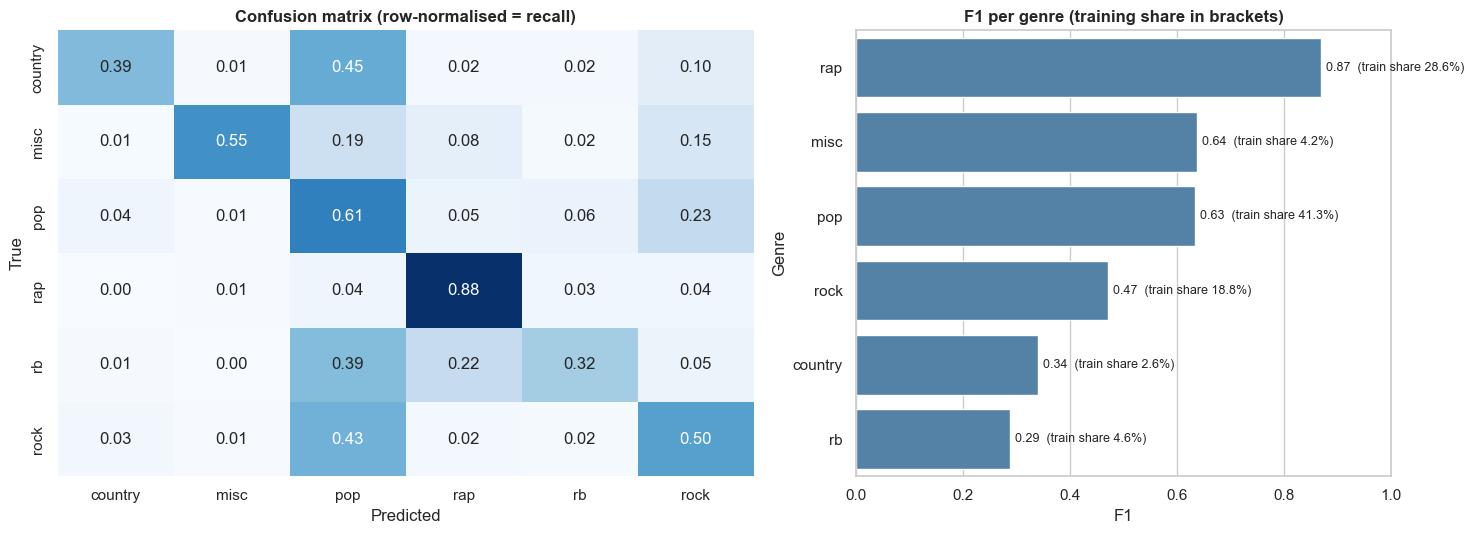

In [7]:
print(classification_report(y_val, pred_offset, target_names=classes, digits=3))

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={'width_ratios': [1.3, 1]})

cm = confusion_matrix(y_val, pred_offset, normalize='true')
sns.heatmap(cm, annot=True, fmt='.2f', cmap='Blues', xticklabels=classes, yticklabels=classes, ax=axes[0], cbar=False)
axes[0].set_title('Confusion matrix (row-normalised = recall)', weight='bold')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('True')

per_class = pd.DataFrame({
    'Genre': classes,
    'F1': f1_score(y_val, pred_offset, average=None),
    'Share of training data': np.bincount(y_tr) / len(y_tr),
}).sort_values('F1', ascending=False)
sns.barplot(data=per_class, x='F1', y='Genre', ax=axes[1], color='steelblue')
for i, row in enumerate(per_class.itertuples()):
    axes[1].text(row.F1 + 0.01, i, f"{row.F1:.2f}  (train share {row._3:.1%})", va='center', fontsize=9)
axes[1].set_xlim(0, 1)
axes[1].set_title('F1 per genre (training share in brackets)', weight='bold')

plt.tight_layout()
plt.show()

**Interpretation.**
- **Overall:** macro-F1 = **0.539**, accuracy = 0.643. Compared with the 0.505 benchmark of `Preprocessing.ipynb`, the full vocabulary, tuning and offsets add +0.034 macro-F1.
- **Rap is by far the easiest genre** (F1 = 0.87): its vocabulary (slang, profanity, rap-specific terms) is very distinctive.
- **`misc` performs well (0.64)** despite being small, because much of it is not song lyrics at all but prose and poetry (see 7.2). Its archaic or formal vocabulary is easy to detect.
- **Pop is the main "attractor"**: 45% of country, 43% of rock and 39% of R&B songs are predicted as pop. Pop is the largest class and covers the same themes (love, heartbreak, dancing), so lyrics alone often cannot tell a pop song from a rock or country ballad.
- **R&B (0.29) and country (0.34) are the hardest.** R&B is also confused with rap (22%), which reflects the real overlap between the two genres.
- **Rock** (0.47) is mostly separated from rap but heavily confused with pop.

These errors reflect real genre overlap more than a modelling failure. Genre is partly defined by sound (instrumentation, rhythm), which lyrics do not capture.

### 7.1 What the model learned

The LinearSVC weights show which terms push a song towards each genre. We list the 12 highest-weighted terms per genre.

In [8]:
feature_names = vec.get_feature_names_out()
top_terms = pd.DataFrame({
    genre: feature_names[np.argsort(-svc.coef_[i])[:12]]
    for i, genre in enumerate(classes)
})
display(top_terms)

,country,misc,pop,rap,rb,rock
0,whiskey,also,chorus,bitch,baby,well
1,old,poem,oh,rap,girl,blood
2,country,whose,dance,shit,babe,burn
3,truck,yet,love,like,ooh,dead
4,ai,may,cos,fuck,gon,void
5,little,however,heart,ai,yeah,bury
6,town,hath,cause,tryna,girl know,sink
7,beer,thus,jesus,yo,feelings,fuck
8,heartaches,nbsp,repeat chorus,verse,wanna,bone
9,well,2,gonna,niggas,dont,drag


The weights are easy to interpret:
- **country**: `whiskey`, `truck`, `town`, `beer`, `bar`, `old`, `heartaches`, the stereotypical rural, nostalgic imagery;
- **rap**: profanity and slang (`tryna`, `yo`, `em`) plus the word `rap` itself;
- **R&B**: intimacy (`baby`, `girl`, `babe`, `feelings`) and vocal fillers (`ooh`, `yeah`);
- **rock**: dark imagery (`blood`, `burn`, `dead`, `bury`, `rot`, `bone`, `void`);
- **misc**: archaic or formal words (`hath`, `thou`, `thus`, `whose`, `however`, `poem`), which confirms it holds many literary texts.

There are also **formatting artefacts**. `chorus` and `repeat chorus` are strong pop indicators: some pop transcriptions write "Repeat Chorus" as plain text instead of a `[Chorus]` tag, so the regex that removes bracketed tags does not catch it. Similarly, `verse` points to rap and `nbsp` (an HTML space) to misc. These terms help on this dataset because the transcription style correlates with the genre, but they are not real lyrical content. A stricter cleaning step could remove them.

### 7.2 Error analysis: the `misc` genre

`misc` has an unusual profile, so we inspect a few validation songs labelled `misc` and what the model predicted for them.

In [9]:
raw_train = pd.read_csv('../dataset/train.csv', usecols=['title', 'artist', 'lyrics', 'tag'])
misc_label = list(classes).index('misc')

val_view = raw_train.iloc[val_idx].assign(pred=classes[pred_offset])
misc_val = val_view[val_view['tag'] == 'misc']
print("Where true `misc` songs end up:")
print(misc_val['pred'].value_counts(normalize=True).round(3).to_string())

print("\nSample of `misc` songs:")
for row in misc_val.sample(6, random_state=RANDOM_STATE).itertuples():
    snippet = ' '.join(str(row.lyrics).split())[:140]
    print(f"- [{row.pred:>7}] {row.title} - {row.artist}: {snippet}...")

Where true `misc` songs end up:
pred
misc       0.550
pop        0.188
rock       0.148
rap        0.084
rb         0.018
country    0.012

Sample of `misc` songs:
- [   misc] Blossoming - Sue Eldredge: You can pry open a rosebud, Pulling its petals apart. The result it will wither and die. It has not unfolded its heart. It takes roots, wate...
- [country] The Jazzy Bard - Franklin P. Adams: Labor is a thing I do not like; Workin's makes me want to go on strike; Sittin' in an office on a sunny afternoon, Thinkin o' nothin' but a ...
- [    rap] FAWM 01 Vote for Your Favorite Title - Melissa Schiller & the Baker-Miller Pinks: Today I heard the news and had a thought Something about this might make a good song People doing stupid shit and getting away with it In Am...
- [    pop] You Can Call Me Allocator - Casper Skulls: In a half century, I'm in the obituaries Crumpled up, saved by hoarders Memories are for the mourners Modern prosperity, let go of clarity L...
- [   misc] PSAL. II Don

The sample confirms that `misc` is mostly **literary text**: poems (Milton's psalm translation, Franklin P. Adams), prose and amateur songwriting posts. The 55% recall comes from the clearly literary texts with archaic vocabulary. The misclassified ones are modern poems or lyrics that read like ordinary pop or rock songs, and the model cannot separate them on vocabulary alone.

### 7.3 Exploratory: adding metadata

We also tested appending the scaled metadata (release year, log views, has_features) from `Preprocessing.ipynb` to the TF-IDF matrix, with the metadata columns weighted by 0.1, 0.3 and 1. In a prototype run, the best weighting improved validation macro-F1 by only about **+0.001** (no offsets), a negligible gain. Because the task is lyrics-based classification, we keep the text-only model. The code is kept below, commented.

In [11]:
# from scipy.sparse import hstack, csr_matrix
# from sklearn.preprocessing import StandardScaler
# meta_df = pd.read_csv('../dataset/train.csv', usecols=['year', 'views', 'features'])
# meta = np.c_[
#     meta_df['year'].where(meta_df['year'].between(1900, 2026), meta_df['year'].median()),
#     np.log1p(meta_df['views'].clip(lower=0)),
#     (meta_df['features'].fillna('{}') != '{}').astype(float),
# ]
# scaler = StandardScaler().fit(meta[train_idx])
# for w in [0.1, 0.3, 1.0]:
#     A_tr = hstack([X_tr, csr_matrix(scaler.transform(meta[train_idx]) * w)]).tocsr()
#     A_val = hstack([X_val, csr_matrix(scaler.transform(meta[val_idx]) * w)]).tocsr()
#     m = LinearSVC(C=0.1, class_weight='balanced').fit(A_tr, y_tr)
#     print(w, round(f1_score(y_val, m.predict(A_val), average='macro'), 4))

## 8. Final Model and Submission

The final pipeline is re-fitted on **all** 134,967 training songs with the selected configuration:
- TF-IDF with unigrams and bigrams, `min_df=2`, `max_df=0.85`, sublinear TF, no Chi-squared selection.
- LinearSVC with `C=0.1` and `class_weight='balanced'`.
- The per-class offsets tuned in Section 6.

We then predict the test set and write `submissions/submission.csv` in the `sample_submission.csv` format.

In [10]:
final_vec = TfidfVectorizer(**tfidf_params)
X_full = final_vec.fit_transform(X_text)
X_test = final_vec.transform(X_test_text)

final_svc = LinearSVC(C=best_C, class_weight='balanced').fit(X_full, y)
test_pred = classes[(final_svc.decision_function(X_test) + offsets).argmax(1)]

submission = pd.DataFrame({'id': test_ids, 'tag': test_pred})
sample = pd.read_csv('../dataset/sample_submission.csv')
submission = sample[['id']].merge(submission, on='id', how='left')
assert len(submission) == len(sample) and submission['tag'].notna().all()

os.makedirs('../submissions', exist_ok=True)
submission.to_csv('../submissions/submission.csv', index=False)
print(f"Saved {len(submission):,} predictions to ../submissions/submission.csv")

dist = pd.DataFrame({
    'Train share': pd.Series(classes[y]).value_counts(normalize=True),
    'Predicted test share': submission['tag'].value_counts(normalize=True),
}).round(3)
display(dist)

Saved 33,742 predictions to ../submissions/submission.csv


,Train share,Predicted test share
country,0.026,0.034
misc,0.042,0.033
pop,0.413,0.374
rap,0.286,0.294
rb,0.046,0.054
rock,0.188,0.211


The predicted test distribution is close to the training distribution, so the model is not collapsing onto the majority class. Pop is slightly under-predicted (37% vs. 41%), and rock, country and R&B slightly over-predicted, a direct result of the balanced class weights and the offsets, which favour minority-class recall to maximise macro-F1.

**Summary of the genre identification part**

| Step | Validation Macro-F1 |
|---|---|
| Preprocessing benchmark (TF-IDF, 5k features, SGD) | 0.505 |
| Full vocabulary (1–2 grams, `min_df=2`) + LinearSVC | 0.528 |
| + per-class decision offsets (final) | **0.539** |

Stratified 3-fold CV over the whole training set gave 0.525 ± 0.003 for the same configuration without offsets, close to the hold-out score, so the hold-out estimate is stable.